NAME : CATHERINE JOSEPH LWEHUMBIZA
REG NO 240242457000
CLASS:BENG24COE_3

TASK 2.1

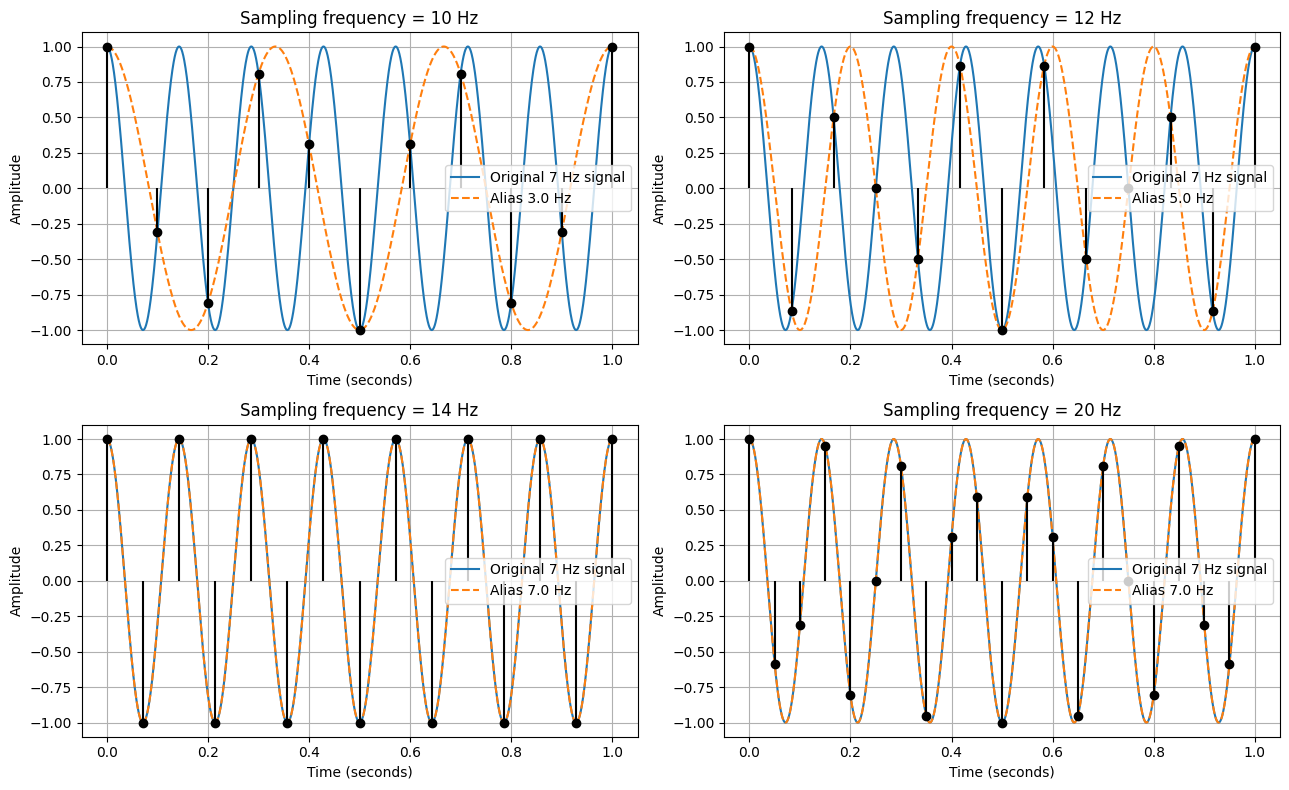

Sampling Frequency | Alias Frequency
               10 | 3.00 Hz
               12 | 5.00 Hz
               14 | 7.00 Hz
               20 | 7.00 Hz


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Original signal frequency
f0 = 7.0

# Different sampling frequencies
sampling_rates = [10, 12, 14, 20]

# Dense time axis for the original signal
t = np.linspace(0, 1, 2000)

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

alias_results = []

for ax, fs in zip(axes.flatten(), sampling_rates):

    # Calculate alias frequency
    f_alias = abs(f0 - fs * round(f0/fs))

    # Sampling index
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Original continuous-looking signal
    x = np.cos(2*np.pi*f0*t)

    # Sampled signal
    xn = np.cos(2*np.pi*f0*tn)

    # Plot original signal
    ax.plot(t, x, label="Original 7 Hz signal")

    # Plot alias signal
    ax.plot(t, np.cos(2*np.pi*f_alias*t),
            "--", label=f"Alias {f_alias:.1f} Hz")

    # Plot sample points
    ax.stem(tn, xn, linefmt="k-",
            markerfmt="ko", basefmt=" ")

    ax.set_title(f"Sampling frequency = {fs} Hz")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid()

    alias_results.append((fs, f_alias))

plt.tight_layout()
plt.show()

# Display alias frequency table
print("Sampling Frequency | Alias Frequency")
for fs, fa in alias_results:
    print(f"{fs:17} | {fa:.2f} Hz")

Expected alias frequency table
Sampling frequency	Alias frequency
10 Hz	3 Hz
12 Hz	5 Hz
14 Hz	7 Hz
20 Hz	7 Hz

Task 2.2

In [ ]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Load my own voice recording
x, fs = librosa.load("my_voice.wav.m4a", sr=None)

print("Original sampling frequency:", fs)
print("Original samples:", len(x))
print("Original duration:", len(x)/fs, "seconds")

# Perform decimation
for k in [2, 4, 8]:

    # Naive downsampling
    naive = x[::k]

    # Proper decimation using anti-aliasing filter
    proper = signal.decimate(x, k, ftype='fir')

    new_fs = fs / k

    print("\nDecimation factor:", k)
    print("New sampling frequency:", new_fs)
    print("Naive samples:", len(naive))
    print("Proper samples:", len(proper))

    print("Naive downsampling audio:")
    display(Audio(naive, rate=int(new_fs)))

    print("Proper decimation audio:")
    display(Audio(proper, rate=int(new_fs)))

/tmp/ipykernel_6449/3397619077.py:8: UserWarning: PySoundFile failed. Trying audioread instead.
  x, fs = librosa.load("my_voice.wav.m4a", sr=None)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Original sampling frequency: 48000
Original samples: 179200
Original duration: 3.7333333333333334 seconds

Decimation factor: 2
New sampling frequency: 24000.0
Naive samples: 89600
Proper samples: 89600
Naive downsampling audio:


Proper decimation audio:



Decimation factor: 4
New sampling frequency: 12000.0
Naive samples: 44800
Proper samples: 44800
Naive downsampling audio:


Proper decimation audio:



Decimation factor: 8
New sampling frequency: 6000.0
Naive samples: 22400
Proper samples: 22400
Naive downsampling audio:


Proper decimation audio:


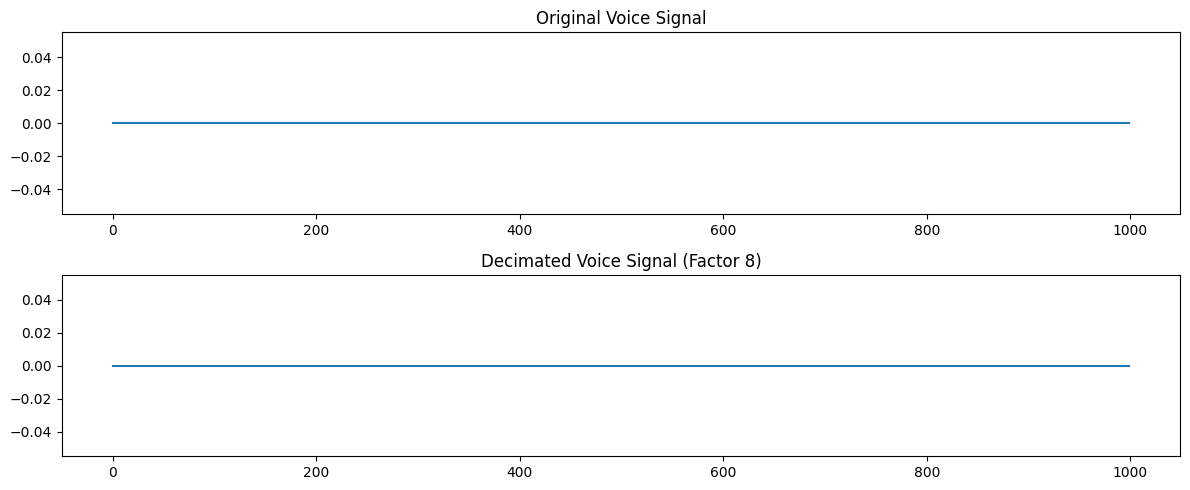

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(2, 1, 1)
plt.plot(x[:1000])
plt.title("Original Voice Signal")

plt.subplot(2, 1, 2)
plt.plot(proper[:1000])
plt.title("Decimated Voice Signal (Factor 8)")

plt.tight_layout()
plt.show()

Task 2.3

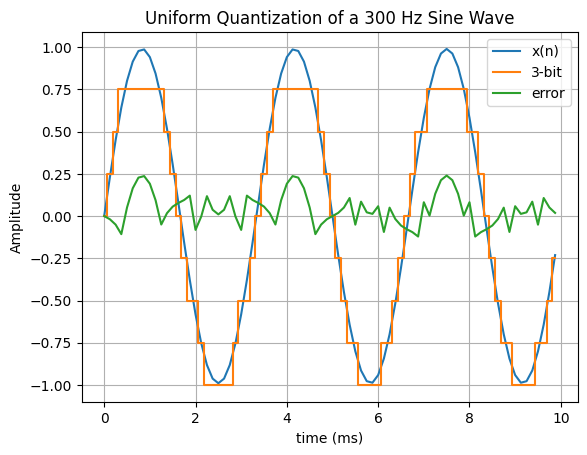

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Uniform quantizer function
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

# Generate a sine wave
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)

# Quantize using 3 bits
xq = quantize(x, 3)

# Plot original signal, quantized signal and error
plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")

plt.xlabel("time (ms)")
plt.ylabel("Amplitude")
plt.title("Uniform Quantization of a 300 Hz Sine Wave")
plt.legend()
plt.grid()
plt.show()

Task 2.4

2 bits: Measured = 9.60 dB, Theoretical = 13.80 dB
4 bits: Measured = 23.58 dB, Theoretical = 25.84 dB
6 bits: Measured = 36.81 dB, Theoretical = 37.88 dB
8 bits: Measured = 48.93 dB, Theoretical = 49.92 dB
10 bits: Measured = 62.81 dB, Theoretical = 61.96 dB
12 bits: Measured = 72.84 dB, Theoretical = 74.00 dB
14 bits: Measured = 88.13 dB, Theoretical = 86.04 dB
16 bits: Measured = 98.91 dB, Theoretical = 98.08 dB


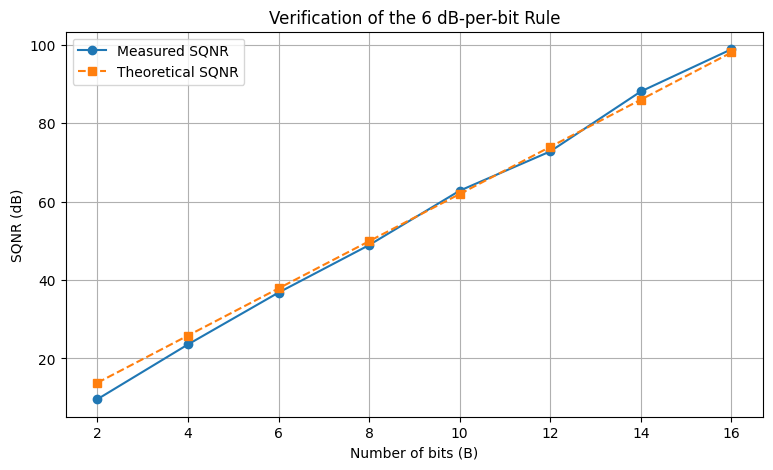

In [ ]:
# Number of bits
bits = np.arange(2, 17, 2)

# Calculate measured SQNR
meas = [
    10*np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

# Calculate theoretical SQNR
theory = 6.02*bits + 1.76

# Display results
for B, M, T in zip(bits, meas, theory):
    print(f"{B} bits: Measured = {M:.2f} dB, Theoretical = {T:.2f} dB")

# Plot results
plt.figure(figsize=(9, 5))
plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theory, "s--", label="Theoretical SQNR")

plt.xlabel("Number of bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Verification of the 6 dB-per-bit Rule")
plt.legend()
plt.grid()
plt.show()

TASK 2.5

In [9]:
import librosa
from IPython.display import Audio, display

# Load my own voice recording
x_voice, fs_voice = librosa.load(
    "my_voice.wav.m4a",
    sr=None
)

# Normalize the voice signal
x_voice = x_voice / np.max(np.abs(x_voice))

# Quantize voice using 4, 8 and 12 bits
voice_bits = [4, 8, 12]

for B in voice_bits:

    # Quantization
    xq_voice = quantize(x_voice, B)

    # Calculate quantization error
    error = x_voice - xq_voice

    # Calculate SQNR
    sqnr = 10*np.log10(
        np.sum(x_voice**2) / np.sum(error**2)
    )

    print(f"\nQuantization using {B} bits")
    print(f"SQNR = {sqnr:.2f} dB")

    # Play quantized voice
    print(f"Listen to voice quantized using {B} bits:")
    display(Audio(xq_voice, rate=fs_voice))

/tmp/ipykernel_6449/3217592761.py:5: UserWarning: PySoundFile failed. Trying audioread instead.
  x_voice, fs_voice = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)



Quantization using 4 bits
SQNR = 12.49 dB
Listen to voice quantized using 4 bits:



Quantization using 8 bits
SQNR = 35.56 dB
Listen to voice quantized using 8 bits:



Quantization using 12 bits
SQNR = 59.60 dB
Listen to voice quantized using 12 bits:


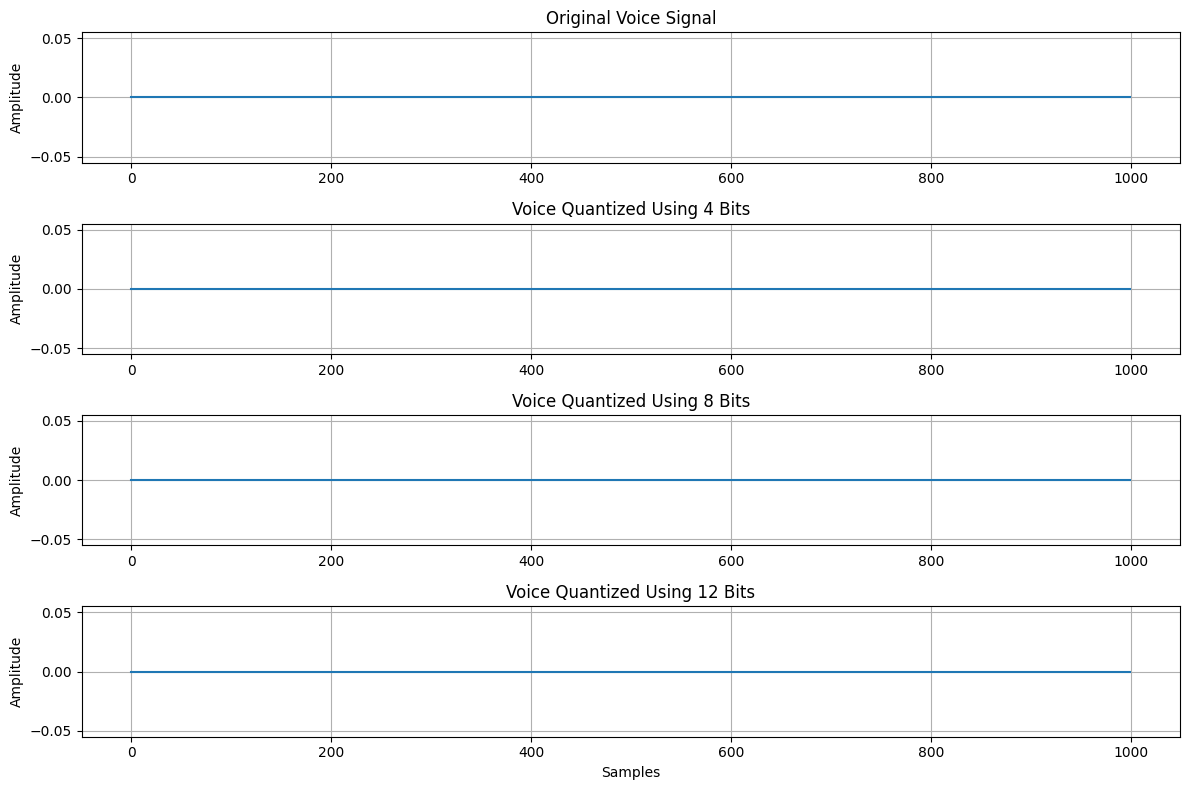

In [10]:
# Store quantized voice signals
quantized_voice = {}

for B in [4, 8, 12]:
    quantized_voice[B] = quantize(x_voice, B)

# Plot original and quantized voice signals
plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.plot(x_voice[:1000])
plt.title("Original Voice Signal")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(4, 1, 2)
plt.plot(quantized_voice[4][:1000])
plt.title("Voice Quantized Using 4 Bits")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(4, 1, 3)
plt.plot(quantized_voice[8][:1000])
plt.title("Voice Quantized Using 8 Bits")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(4, 1, 4)
plt.plot(quantized_voice[12][:1000])
plt.title("Voice Quantized Using 12 Bits")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

WEEK 2: ANALYSIS QUESTIONS AND ANSWERS
Question 1
Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when \(f_s = 10\) Hz.

Answer:

When a 7 Hz signal is sampled at a sampling frequency of 10 Hz, aliasing occurs because the signal frequency is higher than the Nyquist frequency.

The Nyquist frequency is calculated as:
\[
f_N=\frac{f_s}{2}=\frac{10}{2}=5Hz
\]

The alias frequency is:
\[
f_{alias}=|f_0-f_s|
\]

\[
=|7-10|=3Hz
\]

Therefore, the original 7 Hz signal appears as a 3 Hz signal after sampling. This happens because the sampling frequency is not high enough to represent the original signal correctly.

Frequency-axis sketch:
0 Hz       3 Hz       5 Hz       7 Hz       10 Hz
 |----------|----------|----------|-----------|
            Alias     Nyquist    Original


Question 2
In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?

Answer:

Aliasing in the naïve downsampling process cannot be removed afterwards because high-frequency components are mixed with lower-frequency components during sampling. This causes the original frequency information to be lost. Once the signals overlap in the frequency domain, it becomes difficult to separate the original components. Therefore, an anti-aliasing low-pass filter should be applied before downsampling to prevent aliasing.
Question 3
By how much does the SQNR change when one bit is added? Does your measurement agree?

Answer:

Adding one bit increases the theoretical Signal-to-Quantization-Noise Ratio (SQNR) by approximately 6.02 dB. This is because each additional bit doubles the number of quantization levels and reduces the quantization error.

The theoretical SQNR is calculated using:
\[
SQNR=6.02B+1.76
\]

The measured results generally agree with the theoretical rule because the SQNR increases as the number of bits increases. Small differences may occur due to quantization effects and signal characteristics.
Question 4
A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.

Answer:

A suitable sampling rate is 1 sample per second (1 Hz) because the temperature changes slowly at a maximum rate of 0.1 °C per second.

The required number of quantization levels is:
\[
L=\frac{100}{0.01}=10000
\]

The number of bits is calculated using:
\[
B=\lceil\log_2(10000)\rceil
\]

\[
B=14
\]

A 14-bit ADC provides:
\[
2^{14}=16384\text{ levels}
\]

The resolution of a 14-bit ADC over a 100 °C range is approximately:
\[
\Delta=\frac{100}{16384}=0.0061^\circ C
\]

Therefore, a sampling rate of 1 Hz and a 14-bit ADC are suitable because they provide sufficient sampling speed and temperature resolution for the sensor.

## AI-Use Statement

Artificial Intelligence (AI) was used as a learning assistant during this laboratory assignment. It helped in understanding Digital Signal Processing concepts, explaining Python programming code, identifying programming errors and interpreting experimental results. AI assistance was also used to improve the clarity of explanations and answers to analysis questions. All practical tasks were executed using Google Colab, and the results were reviewed and understood before being included in the laboratory report.